# Módulo 10: proyección de puntos fantasy del próximo partido (educativa)

**Preguntas:**
- **J.** ¿Cuánto se equivoca el promedio de la temporada al predecir los puntos fantasy del próximo partido?
- **K.** ¿Predicen mejor los últimos 5 partidos que el promedio de la temporada ("mano caliente")?
- ¿Puede un modelo con minutos, local o visita, descanso y rival mejorarlo? ¿Y qué tan buenos son sus **intervalos**?

**Diseño (decidido antes de ver los datos):**
- Puntos fantasy = `PTS + 1.2·REB + 1.5·AST + 3·ROB + 3·TAP − pérdidas` (la fórmula que publica NBA.com, verificada contra las columnas).
- Filas = "si juega": solo existen partidos jugados. Jugadores con ≥ 15 minutos de promedio en sus últimos 5 partidos y ≥ 5 partidos previos.
- Validación temporal: **Etapa A**, ajustar con 2022-23, calibrar intervalos con 2023-24, validar en 2024-25. **Etapa B**, ajustar con 2022-23 y 2023-24, calibrar con 2024-25, **probar en 2025-26 una sola vez**.
- Baselines primero: promedio de la temporada (con el de la temporada pasada hasta tener 10 partidos), últimos 5, mezcla con contracción, y después una regresión ridge.
- Intervalos: cuantiles empíricos de los errores por nivel de proyección; cobertura medida en datos nuevos.
- Comparaciones pareadas con intervalo bootstrap que remuestrea **jugadores** (los partidos de un mismo jugador no son independientes).

**Mis hipótesis previas:** ninguna ("sin intuición, corre").

**Uso educativo, nunca consejo de apuestas:** no hay líneas de casas de apuestas ni recomendaciones.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sportslab.data import NbaClient
from sportslab.data.gamelog import load_player_games
from sportslab.features.fantasy import FEATURES, build_features, eligible_rows, fill_missing
from sportslab.models.fantasy_model import (
    IntervalCalibrator,
    baseline_last5,
    baseline_season,
    coverage,
    fit_ridge,
    fit_shrinkage,
    paired_abs_error_gain,
    predict_ridge,
    shrunk_mean,
)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.3f}".format
pd.options.display.width = 200

SEASONS = ["2021-22", "2022-23", "2023-24", "2024-25", "2025-26"]
KS = (0, 3, 5, 10, 20, 40, 80)
games = load_player_games(NbaClient(), SEASONS)
rows = fill_missing(eligible_rows(build_features(games)))
rows = rows[rows["season"] != "2021-22"].reset_index(drop=True)
print(f"{len(games):,} filas de partidos jugados; {len(rows):,} elegibles para proyectar")
print(
    f"Puntos fantasy por partido: media {rows['target'].mean():.1f}, desviación {rows['target'].std():.1f}"
)

131,292 filas de partidos jugados; 79,668 elegibles para proyectar
Puntos fantasy por partido: media 25.5, desviación 14.3


## 0. Hallazgos de datos

1. **Un solo endpoint por temporada** trae todos los partidos de todos los jugadores (~26 000 filas) con los puntos fantasy ya calculados; coinciden con la fórmula (el cargador lo verifica y falla si algún día no coincide).
2. **No hay filas de partidos que el jugador no jugó.** Por eso toda proyección es *condicional a que juegue*: un lesionado hoy aparece proyectado igual. NBA.com no tiene partes de lesiones en esta API, y es el límite principal del módulo.
3. **Las variables solo usan partidos anteriores** al proyectado (tests: cambiar el resultado de un partido no mueve sus propias variables). La fuerza del rival (puntos fantasy permitidos) se centra con el promedio de la liga **de fechas anteriores**, no con el de toda la temporada: la primera versión usaba el de toda la temporada, que mira al futuro.

## 1. Cuánto ruido hay (hipótesis J)

In [2]:
def stage(train_seasons, calib_season, score_season):
    train = rows[rows["season"].isin(train_seasons)]
    k = fit_shrinkage(train, KS)
    ridge = fit_ridge(train)

    def predict(frame):
        out = frame[
            ["season", "player_id", "player", "n_prior_season", "min_last5", "target"]
        ].copy()
        out["season_avg"] = baseline_season(frame).to_numpy()
        out["last5"] = baseline_last5(frame).to_numpy()
        out["ewm10"] = frame["last10_ewm"].to_numpy()
        out["shrunk"] = shrunk_mean(frame, k).to_numpy()
        out["ridge"] = predict_ridge(ridge, frame)
        return out

    return (
        k,
        ridge,
        predict(rows[rows["season"] == calib_season]),
        predict(rows[rows["season"] == score_season]),
    )


k_a, ridge_a, calib_a, val = stage(["2022-23"], "2023-24", "2024-25")
k_b, ridge_b, calib_b, test = stage(["2022-23", "2023-24"], "2024-25", "2025-26")
print(f"Contracción elegida: k = {k_a} (etapa A) y k = {k_b} (etapa B)")


def table(score):
    out = {}
    for col in ("season_avg", "last5", "ewm10", "shrunk", "ridge"):
        err = score["target"] - score[col]
        out[col] = {
            "MAE": err.abs().mean(),
            "RMSE": np.sqrt((err**2).mean()),
            "sesgo (pred - real)": -err.mean(),
        }
    return pd.DataFrame(out).T


print("VALIDACIÓN 2024-25")
print(table(val).to_string())
print("\nPRUEBA 2025-26")
print(table(test).to_string())

ss_total = ((test["target"] - test["target"].mean()) ** 2).sum()
r2 = 1 - ((test["target"] - test["season_avg"]) ** 2).sum() / ss_total
print(
    f"\nR² del promedio de la temporada en la prueba: {r2:.2f}  (el {1 - r2:.0%} de la variación entre partidos no se explica)"
)

Contracción elegida: k = 3 (etapa A) y k = 3 (etapa B)
VALIDACIÓN 2024-25


             MAE   RMSE  sesgo (pred - real)
season_avg 8.424 10.690               -0.813
last5      8.653 10.938                0.420
ewm10      8.305 10.497                0.156
shrunk     8.340 10.586               -0.882
ridge      8.137 10.302               -0.252

PRUEBA 2025-26
             MAE   RMSE  sesgo (pred - real)
season_avg 8.423 10.728               -0.672
last5      8.538 10.826                0.411
ewm10      8.225 10.426                0.163
shrunk     8.307 10.580               -0.723
ridge      8.060 10.224               -0.237

R² del promedio de la temporada en la prueba: 0.40  (el 60% de la variación entre partidos no se explica)


**Lectura de J.** El promedio de la temporada se equivoca ~8.4 puntos fantasy por partido (RMSE ~10.7) sobre un promedio de ~25.5; deja sin explicar más de la mitad de la variación entre partidos (R² ≈ 0.4-0.45). Un partido de baloncesto es muy ruidoso aunque conozcas bien al jugador.

## 2. Hipótesis K: ¿mano caliente?

VALIDACIÓN 2024-25 (positivo = mejor que la referencia)


         comparación  mejora del MAE  IC bajo  IC alto
 last5 vs season_avg          -0.230   -0.317   -0.153
 ewm10 vs season_avg           0.118    0.050    0.188
shrunk vs season_avg           0.083    0.059    0.109
 ridge vs season_avg           0.286    0.227    0.352
     ridge vs shrunk           0.203    0.154    0.254

PRUEBA 2025-26
         comparación  mejora del MAE  IC bajo  IC alto
 last5 vs season_avg          -0.115   -0.188   -0.033
 ewm10 vs season_avg           0.198    0.138    0.268
shrunk vs season_avg           0.116    0.085    0.150
 ridge vs season_avg           0.362    0.309    0.430
     ridge vs shrunk           0.246    0.201    0.297


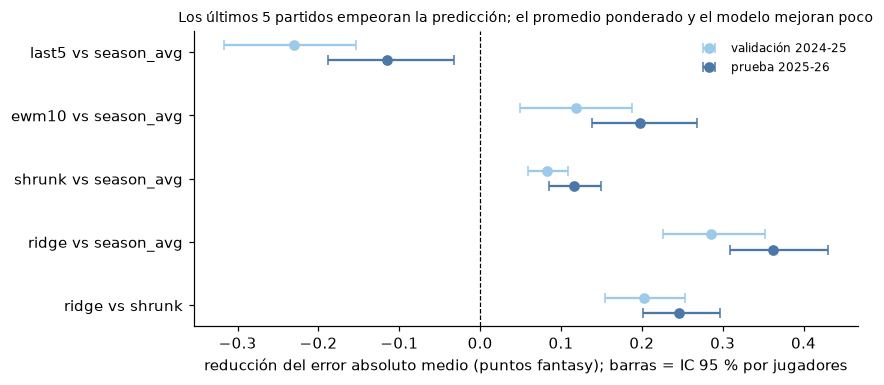

In [3]:
def gains(score):
    out = []
    for new, ref in (
        ("last5", "season_avg"),
        ("ewm10", "season_avg"),
        ("shrunk", "season_avg"),
        ("ridge", "season_avg"),
        ("ridge", "shrunk"),
    ):
        g, lo, hi = paired_abs_error_gain(
            score["target"], score[new], score[ref], score["player_id"]
        )
        out.append(
            {"comparación": f"{new} vs {ref}", "mejora del MAE": g, "IC bajo": lo, "IC alto": hi}
        )
    return pd.DataFrame(out)


gv, gt = gains(val), gains(test)
print("VALIDACIÓN 2024-25 (positivo = mejor que la referencia)")
print(gv.to_string(index=False))
print("\nPRUEBA 2025-26")
print(gt.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(gt))
for df, color, label, off in (
    (gv, "#9ECAE9", "validación 2024-25", -0.12),
    (gt, "#4C78A8", "prueba 2025-26", 0.12),
):
    ax.errorbar(
        df["mejora del MAE"],
        y + off,
        xerr=[df["mejora del MAE"] - df["IC bajo"], df["IC alto"] - df["mejora del MAE"]],
        fmt="o",
        color=color,
        capsize=3,
        label=label,
    )
ax.axvline(0, color="k", ls="--", lw=0.8)
ax.set_yticks(y, gt["comparación"])
ax.invert_yaxis()
ax.set_xlabel("reducción del error absoluto medio (puntos fantasy); barras = IC 95 % por jugadores")
ax.set_title(
    "Los últimos 5 partidos empeoran la predicción; el promedio ponderado y el modelo mejoran poco",
    fontsize=9,
)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Lectura de K.** **La mano caliente de ventana corta no existe**: los últimos 5 partidos, solos, empeoran la predicción (−0.23 en validación y −0.12 en prueba, intervalos que excluyen 0): son un promedio de 5 datos muy ruidosos, y el promedio de toda la temporada tiene más información. Pero **la forma reciente no es inútil**: un promedio con pesos que decaen (≈ últimos 10 partidos, `ewm10`) **sí mejora** al promedio de la temporada (+0.12 en validación y +0.20 en prueba, ambos intervalos por encima de 0) y es la variable con más peso en el modelo. Lo que no sirve es mirar una ventana corta; la ventaja de ponderar por recencia es chica (~2 % del error) pero real. La mezcla con contracción mejora un poco (+0.08, +0.12) y el modelo con minutos, local o visita, descanso y rival mejora algo más (~+0.3 a +0.36 sobre el promedio de la temporada): una reducción de ~4 % del error, real pero modesta. Los coeficientes de variables tan correlacionadas (último 5, ewm10, promedio) no se leen uno por uno.

In [4]:
coef = pd.Series(ridge_b[-1].coef_, index=FEATURES).sort_values()
print("Coeficientes estandarizados de la regresión (prueba, solo para interpretar):")
print(coef.round(2).to_string())

Coeficientes estandarizados de la regresión (prueba, solo para interpretar):
last5               -1.290
rest_days           -0.690
b2b                 -0.120
home                 0.300
n_prior_season       0.360
min_last5            0.690
opp_allowed_rel      0.830
prior_season_mean    1.410
season_mean          2.610
last10_ewm           7.090


## 3. Los intervalos: ¿dicen la verdad?

          conjunto     método  cobertura 50%  cobertura 80%  cobertura 90%  ancho medio 80 %
validación 2024-25 season_avg          0.499          0.798          0.901            26.879
validación 2024-25      ridge          0.499          0.799          0.902            26.076
    prueba 2025-26 season_avg          0.502          0.802          0.898            26.902
    prueba 2025-26      ridge          0.498          0.806          0.903            26.056

Cobertura del rango del 80 % por nivel de proyección (prueba):
                     n  cobertura  proyeccion  ancho
level                                               
(3.975, 16.655]   4087      0.792      13.599 22.870
(16.655, 21.02]   4087      0.805      18.841 24.293
(21.02, 26.059]   4086      0.809      23.433 25.898
(26.059, 33.118]  4087      0.818      29.396 28.018
(33.118, 66.36]   4087      0.806      40.044 29.198


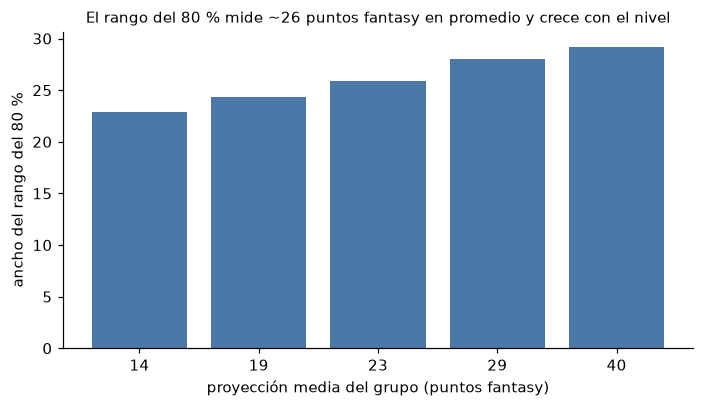

In [5]:
levels = (0.5, 0.8, 0.9)
rows_out = []
for name, calib, score in (("validación 2024-25", calib_a, val), ("prueba 2025-26", calib_b, test)):
    for col in ("season_avg", "ridge"):
        cal = IntervalCalibrator().fit(calib[col], calib["target"])
        row = {"conjunto": name, "método": col}
        for level in levels:
            low, high = cal.interval(score[col].to_numpy(), level)
            row[f"cobertura {level:.0%}"] = coverage(score["target"], low, high)
        low, high = cal.interval(score[col].to_numpy(), 0.8)
        row["ancho medio 80 %"] = float(np.mean(high - low))
        rows_out.append(row)
cov = pd.DataFrame(rows_out)
print(cov.to_string(index=False))

cal = IntervalCalibrator().fit(calib_b["ridge"], calib_b["target"])
low80, high80 = cal.interval(test["ridge"].to_numpy(), 0.8)
test = test.assign(
    inside=(test["target"] >= low80) & (test["target"] <= high80), level=pd.qcut(test["ridge"], 5)
)
by_level = test.groupby("level", observed=True).agg(
    n=("inside", "size"), cobertura=("inside", "mean"), proyeccion=("ridge", "mean")
)
by_level["ancho"] = [
    float(
        np.mean(
            cal.interval(g["ridge"].to_numpy(), 0.8)[1]
            - cal.interval(g["ridge"].to_numpy(), 0.8)[0]
        )
    )
    for _, g in test.groupby("level", observed=True)
]
print("\nCobertura del rango del 80 % por nivel de proyección (prueba):")
print(by_level.to_string())

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(range(len(by_level)), by_level["ancho"], color="#4C78A8")
ax.set_xticks(range(len(by_level)), [f"{p:.0f}" for p in by_level["proyeccion"]])
ax.set_xlabel("proyección media del grupo (puntos fantasy)")
ax.set_ylabel("ancho del rango del 80 %")
test_width = float(np.mean(high80 - low80))
ax.set_title(
    f"El rango del 80 % mide ~{test_width:.0f} puntos fantasy en promedio y crece con el nivel",
    fontsize=10,
)
plt.tight_layout()
plt.show()

**Lectura.** Los intervalos están **bien calibrados** fuera de muestra: el de 50 % acierta ~50 %, el de 80 % ~80 %, y la cobertura es parecida en todos los niveles de proyección. Pero son **muy anchos**: el del 80 % mide ~26 puntos fantasy en promedio (±13 alrededor de una proyección de ~25). Un jugador proyectado en 25 puede hacer 12 o 38 sin sorpresa. El intervalo del modelo es solo un poco más estrecho que el del promedio de la temporada: casi todo el ancho es ruido de un solo partido.

## 4. Al inicio de la temporada (como ahora)

La temporada actual lleva ~7 partidos por jugador. ¿Cómo rinde cada método según cuántos partidos lleva el jugador?

In [6]:
bins = pd.cut(test["n_prior_season"], [-1, 4, 9, 24, 200], labels=["0-4", "5-9", "10-24", "25+"])
rows_b = []
for label, g in test.groupby(bins, observed=True):
    r = {"partidos previos": label, "n": len(g)}
    for col in ("season_avg", "last5", "ewm10", "shrunk", "ridge"):
        r[col] = (g["target"] - g[col]).abs().mean()
    rows_b.append(r)
early = pd.DataFrame(rows_b)
print(early.to_string(index=False))

partidos previos     n  season_avg  last5  ewm10  shrunk  ridge
             0-4  1689       9.000  9.367  8.968   8.378  8.431
             5-9  1644       8.685  8.288  7.955   7.989  7.826
           10-24  5029       8.236  8.449  8.136   8.204  8.013
             25+ 12072       8.384  8.493  8.195   8.383  8.060


Hasta los 10 partidos, "el promedio de la temporada" es en realidad el de la temporada pasada, que a principios de año está desfasado: por eso en el grupo de 5-9 partidos previos los últimos 5 (8.29) le ganan a ese promedio (8.69), aunque pierden contra la contracción (7.99) y el modelo (7.83). En el grupo de 0-4 partidos previos el modelo no mejora a la contracción (8.43 vs. 8.38). La ventaja del modelo aparece desde los 5 partidos. El promedio con pesos decrecientes (`ewm10`) es el mejor método simple en todos los grupos desde los 5 partidos previos, y el modelo lo mejora un poco más.

## 5. Resultado vs. hipótesis

No hubo hipótesis previa. Contra la referencia "el promedio de la temporada":

| Pregunta | Resultado (prueba 2025-26) | Veredicto |
|---|---|---|
| J. Error del promedio de la temporada | ~8.4 puntos fantasy (RMSE ~10.7), sobre un promedio de ~25 | Alto: un partido es muy ruidoso |
| K. ¿Mano caliente? | Últimos 5: empeora el MAE en 0.12 (0.23 en validación). Promedio con pesos decrecientes (~10 partidos): mejora 0.20 (0.12 en validación), ambos con IC sobre 0 | La ventana corta no sirve; la forma reciente suavizada aporta un poco |
| Modelo con minutos, sede, descanso y rival | +0.36 de MAE sobre el promedio (≈ −4 %) | Mejora real pero modesta |
| Intervalos | 50 % → ~50 %, 80 % → ~80 %; ancho ~26 | Bien calibrados, muy anchos |

**Qué NO dice:** que el modelo sirva para decidir nada con dinero. Y la proyección es "si juega": sin lesiones ni rotaciones, que son lo que más mueve un partido concreto.

**Qué mejorar (no hecho):** información de lesiones y alineaciones (lo que más falta); modelar los minutos por separado; distribución completa en vez de cuantiles (por ejemplo, mezclas); validar en más temporadas.

## 6. Tus ejercicios

1. **Predice y mide.** Sube el mínimo de minutos de 15 a 25. Antes de correr, predice si el error absoluto medio sube o baja y si los intervalos se estrechan, y por qué (¿qué pasa con la variación entre partidos de un jugador de rol?).
2. **Mano caliente por partes.** Repite la comparación "últimos 5 vs. promedio" solo para jugadores de ≥ 30 minutos. Predice si el resultado cambia.